# EMOVID → LaBraM：直接从 S3 读取与分析

本 Notebook 读取 `s3://personalized-fm/processed_labram/`，不依赖 FUSE 挂载。
先运行 `python -m preprocessing.labram.emovid_labram` 生成派生数据。

保留 EMOVID 的分段、标签、QC、0.3–75 Hz 滤波和 200 Hz 采样率。
HDF5 保存重新从原始 S3 EEG 重建的**裁剪前 μV**，加载器在模型入口完成一次 `/100`。
`read_window` 用于物理单位下的分析；`dataset[i]['eeg']` 用于直接调用模型。

已有输出由固定内容文件和 ETag 引用；本 Notebook 仅读取数据，不重新运行预处理。

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
import lance, torch
from torch.utils.data import DataLoader
from IPython.display import display

PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                if (p/'preprocessing'/'labram'/'emovid_labram.py').is_file()), None)
if PROJECT is None:
    raise RuntimeError('请在项目根目录或 notebooks/ 目录启动内核')
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))

from preprocessing.labram.labram_dataset import S3LaBraMDataset
from preprocessing.common.emovid_segments import Store
from preprocessing.common.emovid_storage import OutputStore

PROFILE = 'rustfs'
OUTPUT_URI = 's3://personalized-fm/processed_labram'
DEMO_INDEX = None  # None: 第一个通过 QC 的情绪窗口；整数: 全窗口索引
RUN_MODEL_FORWARD = False  # True 会实例化随机初始化的 LaBraM；不会加载预训练权重
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 100})
store = Store(PROFILE)
output = OutputStore(store.s3, OUTPUT_URI)
manifest = output.read_json('manifest.json')
assert manifest['status'] == 'pass'
all_windows = S3LaBraMDataset(output.uri('manifest.json'), profile=PROFILE, qc_only=False, segment_type=None)
training = S3LaBraMDataset(output.uri('manifest.json'), profile=PROFILE)
print('S3:', OUTPUT_URI)
print('全部窗口:', len(all_windows), '| QC-passing emotion:', len(training))
assert len(all_windows) == manifest['n_windows']
assert len(training) == manifest['qc_pass_emotion_count']

S3: s3://personalized-fm/processed_labram
全部窗口: 3026 | QC-passing emotion: 2592


## 1. 标签、质控与来源

主标签 negative=0、neutral=1、positive=2、rest=3；rest 的 `emotion_label` 为空。
训练加载器默认排除 rest 和 QC 失败窗口。所有窗口仍保留在 HDF5 供分析。
元数据中的通道顺序描述原 EMOVID 表；绘图应使用 `read_window` 返回的实际输出 `channel_names`。

,pass,fail,total
label_name,,,
negative,846,103,949
neutral,883,65,948
positive,863,83,946
rest,166,17,183


,recording_name,subject_id,session_id,windows,qc_pass
0,20261022161317_20261022_lwh,13467638,session_01,273,271
1,20261023101920_20261023_lwh,13467638,session_01,10,9
2,20261023102529_20261023_lwh,13467638,session_01,182,179
3,20261023120658_20261023_lwh,13467638,session_01,14,14
4,20261023120658_20261023_lwh,13467638,session_02,56,55
5,20261023133228_20261023_lwh,13467638,session_02,23,20
6,20261023140127_20261023_lwh,13467638,session_02,136,135
7,20261023155133_20261023_lwh,13467638,session_02,11,11
8,20261026102745_20261026_lwh,13467638,session_03,85,71
9,20261026111359_20261026_lwh,13467638,session_03,192,188


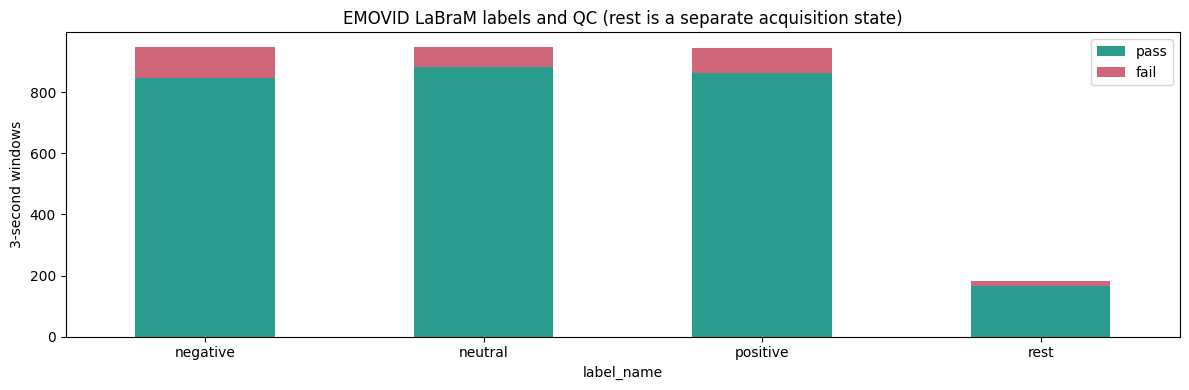

In [2]:
rows = pd.DataFrame(all_windows.metadata())
rows['dataset_index'] = np.arange(len(rows))
counts = pd.crosstab(rows.label_name, rows.qc_pass).reindex(columns=[True, False], fill_value=0)
counts.columns = ['pass', 'fail']
counts['total'] = counts['pass'] + counts['fail']
display(counts)
display(rows.groupby(['recording_name', 'subject_id', 'session_id']).agg(
    windows=('sample_id', 'size'), qc_pass=('qc_pass', 'sum')).reset_index())
counts[['pass', 'fail']].plot.bar(stacked=True, color=['#2a9d8f', '#cf6679'], rot=0)
plt.ylabel('3-second windows')
plt.title('EMOVID LaBraM labels and QC (rest is a separate acquisition state)')
plt.tight_layout()
plt.show()

## 2. μV 波形、频谱和模型缩放

每个窗口严格为 3 秒、59 通道、600 个采样点，没有补零。
波形和 PSD 使用 μV，模型输入为 μV/100，避免把归一化后的数值当成 μV。

emovid#5dbe735ab8f4977d2f637cea | label: positive | qc_pass: True
物理波形: (59, 600) uV; 模型输入: (59, 3, 200) uV/100


,value
subject_id,13467638
session_id,session_01
run_id,1
video_id,emotion:00029995.mp4
start_time,903.975
duration,3.0
clip_fraction,0.000311
qc_reasons,[]
events_uri,s3://oi-data/EMOVID-261029/13467638/session_01...


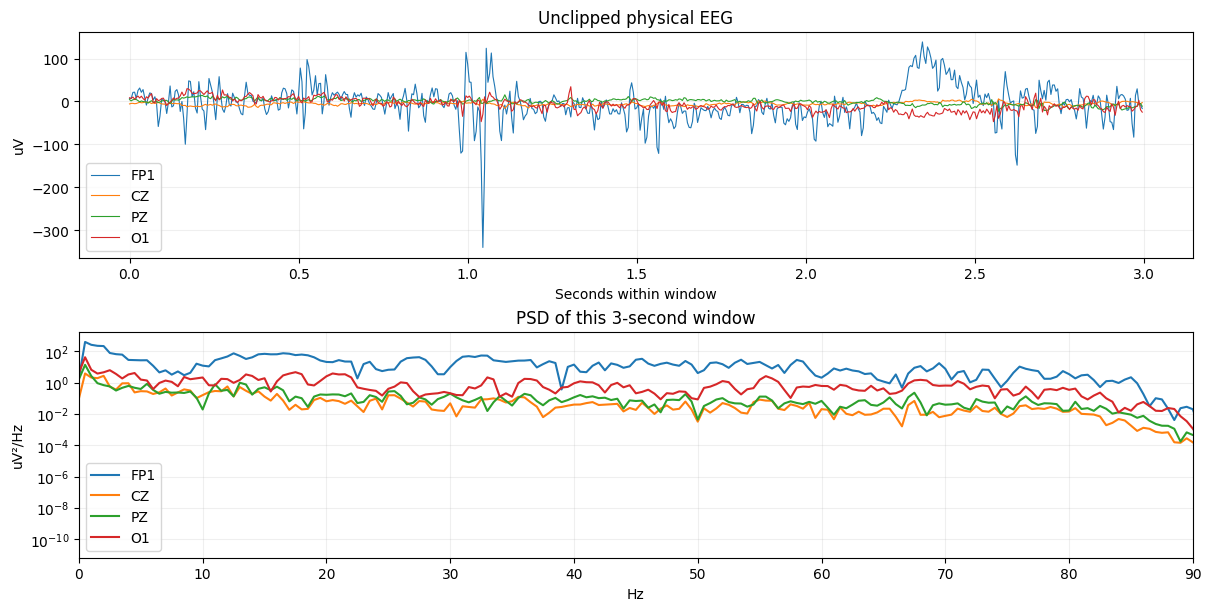

In [3]:
if DEMO_INDEX is None:
    demo_index = int(rows.index[rows.qc_pass & rows.segment_type.eq('emotion')][0])
else:
    demo_index = int(DEMO_INDEX)
window = all_windows.read_window(demo_index)
eeg_uv, names = window['eeg_uv'], window['channel_names']
meta = window['metadata']
assert eeg_uv.shape == (59, 600) and np.isfinite(eeg_uv).all()
x = all_windows[demo_index]['eeg'].numpy()
np.testing.assert_array_equal(x.reshape(59, 600), eeg_uv/100)
print(meta['sample_id'], '| label:', meta['label_name'], '| qc_pass:', meta['qc_pass'])
print('物理波形:', eeg_uv.shape, 'uV; 模型输入:', x.shape, 'uV/100')
display(pd.Series({k: meta[k] for k in ['subject_id', 'session_id', 'run_id', 'video_id',
    'start_time', 'duration', 'clip_fraction', 'qc_reasons', 'events_uri']}).to_frame('value'))

selected = [name for name in ['FP1', 'CZ', 'PZ', 'O1'] if name in names]
times = np.arange(600)/200
fig, axes = plt.subplots(2, 1, figsize=(12, 6), layout='constrained')
for name in selected:
    index = names.index(name)
    axes[0].plot(times, eeg_uv[index], lw=.8, label=name)
    frequencies, psd = signal.welch(eeg_uv[index], fs=200, nperseg=400)
    axes[1].semilogy(frequencies, psd, label=name)
axes[0].set(xlabel='Seconds within window', ylabel='uV', title='Unclipped physical EEG')
axes[1].set(xlabel='Hz', ylabel='uV²/Hz', xlim=(0, 90), title='PSD of this 3-second window')
for ax in axes:
    ax.legend()
    ax.grid(alpha=.2)
plt.show()

## 3. 对照原 S3 Lance 的窗口

按原始 `sample_id` 读取固定版本 Lance，恢复原通道顺序后比较。
原 Lance 已经裁剪，比较的是 `clip(reconstructed_uV/200,-1,1)`。
HDF5 以 float32 保存 μV，二次编码可能有 float32 舍入误差，允许绝对误差 `1e-7`。
转换器在写入 HDF5 **之前**使用 float64 重建波形做过所有窗口的逐值精确核对。

In [4]:
record = next(r for r in manifest['recordings'] if r['recording_name'] == window['recording_name'])
source = OutputStore(store.s3, record['source_uri'])
source_table = lance.dataset(record['source_lance_uri'], version=record['source_lance_version'],
                             storage_options=source.options)
sample_id = meta['sample_id'].replace("'", "''")
source_row = source_table.to_table(filter=f"sample_id = '{sample_id}'",
                                   columns=['data', 'shape', 'channel_names']).to_pylist()
assert len(source_row) == 1
original = np.asarray(source_row[0]['data'], dtype=np.float32).reshape(source_row[0]['shape'])
inverse = np.argsort(record['channel_permutation'])
reencoded = np.clip(eeg_uv[inverse]/200, -1, 1)
np.testing.assert_allclose(reencoded, original, atol=1e-7, rtol=0)
print('原 Lance 固定版本:', record['source_lance_version'])
print('所选窗口再编码最大误差:', float(abs(reencoded-original).max()))
print('全量转换时精确核对窗口数:', sum(r['verified_source_windows'] for r in manifest['recordings']))

原 Lance 固定版本: 1
所选窗口再编码最大误差: 5.960464477539063e-08
全量转换时精确核对窗口数: 3026


## 4. 输入 LaBraM

`batch['eeg']` 已经是 `[B,59,3,200]`、μV/100，直接传入模型即可。
模型位置索引用 `training.input_chans`，与保存的通道顺序一致。
本项目模型设置 `num_patches_per_channel_input=3`；如需预训练特征，还需加载并适配相应 checkpoint。

下方可选前向只检查接口，不代表预训练特征或分类性能。
使用官方训练循环时，循环内部已有 `/100` 和 reshape，应向它提供未缩放的 μV 窗口。

In [5]:
batch = next(iter(DataLoader(training, batch_size=2, shuffle=False, num_workers=0)))
assert tuple(batch['eeg'].shape) == (2, 59, 3, 200)
assert batch['label'].dtype == torch.long
print('Batch:', batch['eeg'].shape, '| labels:', batch['label'].tolist())
print('input_chans:', len(training.input_chans), '| CLS:', training.input_chans[0])
if RUN_MODEL_FORWARD:
    from src.modeling_finetune import labram_base_patch200_200
    model = labram_base_patch200_200(num_classes=3, num_patches_per_channel_input=3, init_values=.1)
    model.eval()
    with torch.no_grad():
        logits = model(batch['eeg'], input_chans=training.input_chans)
    assert tuple(logits.shape) == (2, 3) and torch.isfinite(logits).all()
    print('随机初始化模型前向:', logits.shape)

Batch: torch.Size([2, 59, 3, 200]) | labels: [2, 2]
input_chans: 60 | CLS: 0


## 5. 数据划分与资源释放

`split` 仍为 `unspecified`。正式训练时应按被试、session 或视频分组划分，
避免将同一视频的相邻窗口随机分散到训练集和测试集。
HDF5 与 S3 客户端由每个 DataLoader worker 独立打开；波形只保存在有界内存缓存中。

实现：[转换器](../preprocessing/labram/emovid_labram.py)、[S3 加载器](../preprocessing/labram/labram_dataset.py)、
[输入与命令说明](../PREPROCESS_LABRAM.md)。

In [6]:
all_windows.close()
training.close()
print('S3 HDF5 读取句柄已关闭。')

S3 HDF5 读取句柄已关闭。
